The notebook provides quantitative validation of GloFAS discharge data against observation datasets.
1. Global River Data Center (GRDC) hydrological observation database. The database is the most comprehensive global dataset of hydrological records. The data are openly available and can be obtained upon request (normally satisfied ina few minutes).
2. Zambezi River Authority (ZRA) data. This database contains Zambia-specific observation records which are openly availably but require some additional preprocessing.


In [1]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import numpy as np
import pandas as pd
import xarray as xr

from matplotlib.backends.backend_pdf import PdfPages
from matplotlib.lines import Line2D
from pathlib import Path
from scipy.spatial import cKDTree

from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

In [2]:
glofas_dir = "GloFAS/v5"

grdc_dir = "GRDC"
grdc_csv = Path(grdc_dir, "GRDC-Daily.nc")
grdc_meta_fl = Path(grdc_dir, "stationbasins.geojson")

zar_dir = "Zambezi River Authority"

# Read data

## GloFAS

Orignal GloFAS data files used for discharge [m^3/s] and runoff [m]. The files are availabile by years and must be concatenated when loading.

In [3]:
glofas_files = sorted(Path(glofas_dir).glob("*discharge.nc"))
glofas_runoff_files = sorted(Path(glofas_dir).glob("*runoff.nc"))

In [4]:
glofas_xr = xr.open_mfdataset(
    glofas_files,
    combine="by_coords",
    data_vars="minimal",
    coords="minimal",
    compat="no_conflicts",
)

glofas_runoff_xr = xr.open_mfdataset(
    glofas_runoff_files,
    combine="by_coords",
    data_vars="minimal",
    coords="minimal",
    compat="no_conflicts",
)

## Read meta data of observation datasets

### GRDC Data

GRDC stations data can be downloaded from GRDC website.

In [5]:
grdc_meta = pd.read_json(grdc_meta_fl, typ="series")

In [6]:
if "features" not in grdc_meta or "geometryType" not in grdc_meta:
    raise ValueError("Expected the supplied GRDC Esri JSON station file")

gr = pd.DataFrame([feature["attributes"] for feature in grdc_meta["features"]])
grdc_stations = pd.DataFrame({
    "source": "GRDC",
    "station_id": gr["grdc_no"].astype("Int64").astype(str),
    "station_name": gr["station"],
    "river": gr["river"],
    "lat": pd.to_numeric(gr["lat_org"], errors="coerce"),
    "lon": pd.to_numeric(gr["long_org"], errors="coerce"),
    "area_km2": pd.to_numeric(gr["area"], errors="coerce"),
    "quality": gr["quality"],
}).dropna(subset=["lat", "lon"])

### Zambezi River Authority Data

Coordinates of ZRA stations have been restored manually.

In [7]:
zra_stations = {
    "Victoria_Falls": (-17.93050, 25.85980),
    "Ngonye_Falls": (-16.64316, 23.55763),
    "Nana_Farn": (-17.82802, 25.65121),
    # Observations haven't been extracted
    #"Victoria Falls Big Tree": (-17.92000, 25.83000),
    "Chavuma": (-13.08380, 22.67684),
}

In [8]:
zra_stations

{'Victoria_Falls': (-17.9305, 25.8598),
 'Ngonye_Falls': (-16.64316, 23.55763),
 'Nana_Farn': (-17.82802, 25.65121),
 'Chavuma': (-13.0838, 22.67684)}

In [9]:
zra_stations = pd.DataFrame([
    {
        "source": "ZRA",
        # TODO Extract ids for ZRA data
        "station_id": pd.NA,
        "station_name": name,
        "river": "Zambezi",
        "lat": lat,
        "lon": lon
    }
    for name, (lat, lon) in zra_stations.items()
])

Consolidated observation dataset of GRDC and ZRA metadata:

In [10]:
measurement_stations = (
    pd.concat([grdc_stations, zra_stations], ignore_index=True)
)

In [11]:
measurement_stations.head(3)

,source,station_id,station_name,river,lat,lon,area_km2,quality
0,GRDC,1547100,CHUNGA RANCH,KALUNGU,-9.9300,32.1300,-999.0,High
1,GRDC,1547200,NSAMA,MWAMBESHI,-8.9000,29.9666,707.0,Low
2,GRDC,1547201,CHIPILI,LUFUBU,-10.7166,29.0833,1220.0,Low


In [12]:
measurement_stations.tail(3)

,source,station_id,station_name,river,lat,lon,area_km2,quality
74,ZRA,<NA>,Ngonye_Falls,Zambezi,-16.64316,23.55763,NaN,NaN
75,ZRA,<NA>,Nana_Farn,Zambezi,-17.82802,25.65121,NaN,NaN
76,ZRA,<NA>,Chavuma,Zambezi,-13.08380,22.67684,NaN,NaN


#### Plotting

This part provides an overview of spatial distribution of the measurment stations in the both observation networks.

In [13]:
def truncate_colormap(cmap_name, minval=0.0, maxval=1.0, n=256):
    cmap = plt.get_cmap(cmap_name)
    new_colors = cmap(np.linspace(minval, maxval, n))
    return mcolors.LinearSegmentedColormap.from_list(
        f"trunc({cmap_name},{minval:.2f},{maxval:.2f})",
        new_colors
    )

cmap_saturated_blues = truncate_colormap("Blues", minval=0.25, maxval=1.0)
cmap_blue_ocean = truncate_colormap("ocean_r", minval=0.05, maxval=0.75)
cmap_bright_gnbu = truncate_colormap("GnBu", minval=0.5, maxval=1.0)

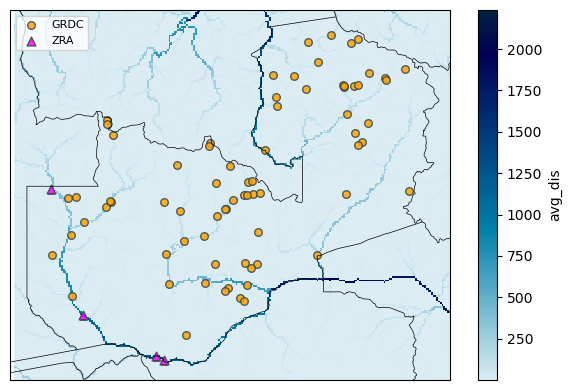

In [14]:
fig, ax = plt.subplots(
    figsize=(6, 4),
    subplot_kw={"projection": ccrs.PlateCarree()},
)

(
    glofas_xr["avg_dis"]
    .mean(dim="valid_time")
    .plot(
        ax=ax,
        cmap=cmap_blue_ocean,
        alpha=1,
        transform=ccrs.PlateCarree(),
    )
)

ax.add_feature(
    cfeature.BORDERS,
    edgecolor="black",
    linewidth=0.5,
)

for source, color, marker, size in [
    ("GRDC", "orange", "o", 30),
    ("ZRA", "magenta", "^", 40),
]:
    sub = measurement_stations[
        measurement_stations["source"] == source
    ]

    ax.scatter(
        sub["lon"],
        sub["lat"],
        marker=marker,
        s=size,
        facecolor=color,
        edgecolor="#36454F",
        alpha=0.85,
        label=source,
        transform=ccrs.PlateCarree(),
    )

ax.set_extent(
    [21.5, 34, -18.5, -8],
    crs=ccrs.PlateCarree(),
)

ax.set_title("")

ax.legend(loc="upper left", fontsize=8)

plt.tight_layout()
plt.show()

## Read Observation Records

Time-series of the daily discharge must be read from the both databases.

### Zambezi River Authority

The ZRA data format follows the original dataset with some manual adjustments introduced during preprocessing.

In [15]:
def read_observations_zra(csv_file):
    """
    Read ZRA daily discharge observations into a pandas.Series.
    """
    df = pd.read_csv(
        csv_file,
        sep=";",
        usecols=["Date", "Flow (m3/s)"],
        dtype=str,
    )

    df["time"] = pd.to_datetime(
        df["Date"],
        dayfirst=True,
        errors="coerce",
    )

    df["runoff_mean"] = pd.to_numeric(
        df["Flow (m3/s)"].str.replace(",", "", regex=False),
        errors="coerce",
    )

    return (
        df.dropna(subset=["time"])
        .groupby("time")["runoff_mean"]
        .mean()
        .sort_index()
    )

In [16]:
observations_zra = {}

for station in zra_stations["station_name"]:
    csv_file = Path(zar_dir, f"{station}.csv")

    if not csv_file.exists():
        print(f"No observations available for {station}")
        continue

    observations_zra[station] = read_observations_zra(csv_file)

In [17]:
observations_zra_df = pd.DataFrame(observations_zra)

In [18]:
observations_zra_df.head(2)

,Victoria_Falls,Ngonye_Falls,Nana_Farn,Chavuma
time,,,,
2019-01-14,416.0,488.0,410.0,256.0
2019-01-15,426.0,487.0,416.0,267.0


### GRDC

GRDC records are stored in the original NetCDF format.

In [19]:
grdc_xr = xr.open_dataset(grdc_csv)
st_names_list = grdc_xr["station_name"].values.tolist()

In [20]:
grdc_xr

<xarray.Dataset> Size: 7MB
Dimensions:              (time: 23727, id: 72)
Coordinates:
  * time                 (time) datetime64[ns] 190kB 1941-01-15 ... 2005-12-31
  * id                   (id) int64 576B 1547100 1547200 ... 1591810 1591820
Data variables:
    runoff_mean          (time, id) float32 7MB ...
    area                 (id) float32 288B ...
    country              (id) <U2 576B ...
    geo_x                (id) float32 288B ...
    geo_y                (id) float32 288B ...
    geo_z                (id) float32 288B ...
    owneroforiginaldata  (id) <U85 24kB ...
    river_name           (id) <U13 4kB ...
    station_name         (id) <U37 11kB 'CHUNGA RANCH' 'NSAMA' ... 'KALABO'
    timezone             (id) float32 288B ...
Attributes:
    title:          Mean daily discharge (Q)
    Conventions:    CF-1.7
    references:     grdc.bafg.de
    institution:    GRDC
    history:        Download from GRDC Database, 08/04/2026
    missing_value:  -999.000

## Validation

Quality of the gridded GloFAS inflow data is estimated by direct comparison with the observations data using indicators normally used for hydrological forecasts.

In [21]:
def calculate_validation_metrics(observed, simulated):
    """
    Calculate hydrological validation metrics along the time dimension.

    KGE follows Gupta et al. (2009).
    NSE follows Nash and Sutcliffe (1970).
    PBIAS follows Moriasi et al. (2007), where positive
    values indicate underestimation.

    Parameters
    ----------
    observed, simulated : xarray.DataArray
        Observed and simulated discharge with a common time
        dimension and aligned coordinates.

    Returns
    -------
    xarray.Dataset
        Validation metrics for each station.
    """

    valid = (
        np.isfinite(observed)
        & np.isfinite(simulated)
        & (observed >= 0)
        & (simulated >= 0)
    )

    obs = observed.where(valid)
    sim = simulated.where(valid)

    n = valid.sum(dim="time")

    obs_mean = obs.mean(dim="time")
    sim_mean = sim.mean(dim="time")

    obs_std = obs.std(dim="time")
    sim_std = sim.std(dim="time")

    # Error metrics
    error = sim - obs
    mse = (error**2).mean(dim="time")
    rmse = np.sqrt(mse)
    mae = abs(error).mean(dim="time")
    pbias = 100 * (obs_mean - sim_mean) / obs_mean.where(
        obs_mean > 0
    )    

    r = xr.corr(obs, sim, dim="time")

    # Kling-Gupta Efficiency
    alpha = sim_std / obs_std.where(obs_std > 0)
    beta = sim_mean / obs_mean.where(obs_mean > 0)
    kge = 1 - np.sqrt(
        (r - 1) ** 2
        + (alpha - 1) ** 2
        + (beta - 1) ** 2
    )

    # Nash-Sutcliffe Efficiency
    nse = 1 - mse / (obs_std**2).where(obs_std > 0)

    return xr.Dataset(
        {
            "n": n,
            "r": r,
            "RMSE": rmse,
            "MAE": mae,
            "PBIAS (%)": pbias,            
            "KGE": kge,
            "alpha": alpha,
            "beta": beta,
            "NSE": nse,            
        }
    )

A dedicated parser function is used for each observation dataset.

In [22]:
def validate_zra_glofas(
    observations_zra,
    zra_stations,
    glofas_xr,
    min_days=365,
):
    """
    Validate GloFAS daily discharge against ZRA observations.

    Parameters
    ----------
    observations_zra : pandas.DataFrame
        Daily discharge observations, indexed by date, with
        station names as columns.
    zra_stations : pandas.DataFrame
        Station metadata containing station_name, lon, and lat.
    glofas_xr : xarray.Dataset
        GloFAS discharge containing avg_dis.
    min_days : int, optional
        Minimum number of overlapping valid daily observations.

    Returns
    -------
    pandas.DataFrame
        Station-level validation metrics and coordinates.
    """

    # Prepare observations without modifying the input
    observations_df = observations_zra.copy()
    observations_df.index = pd.to_datetime(observations_df.index)

    observed = xr.DataArray(
        observations_df.to_numpy(),
        dims=("time", "station_name"),
        coords={
            "time": observations_df.index,
            "station_name": observations_df.columns,
        },
    )

    stations = zra_stations.set_index("station_name").loc[
        observed["station_name"].values
    ]

    lon = xr.DataArray(
        stations["lon"].values,
        dims="station_name",
        coords={"station_name": observed["station_name"]},
    )

    lat = xr.DataArray(
        stations["lat"].values,
        dims="station_name",
        coords={"station_name": observed["station_name"]},
    )

    simulated = (
        glofas_xr["avg_dis"]
        .sel(
            latitude=lat,
            longitude=lon,
            method="nearest",
        )
        .rename(valid_time="time")
    )

    # Joining aligns time coordinates
    observed, simulated = xr.align(
        observed,
        simulated,
        join="inner",
    )

    results = calculate_validation_metrics(observed, simulated)

    results = results.assign(
        lon=lon,
        lat=lat,
    )

    results_df = results.to_dataframe().reset_index()
    results_df["source"] = "ZRA"

    return results_df.loc[results_df["n"] >= min_days]

In [23]:
def validate_grdc_glofas(grdc_df, glofas_xr, min_days=365):
    """
    Validate GloFAS daily discharge against all GRDC stations.

    GloFAS is sampled at the nearest grid cell to each GRDC station.
    Performance metrics are calculated along the common time dimension.

    Parameters
    ----------
    grdc_df : xarray.Dataset
        GRDC observations containing runoff_mean, geo_x, geo_y,
        and station_name, with dimensions (time, id).
    glofas_xr : xarray.Dataset
        GloFAS discharge containing avg_dis, with dimensions
        (valid_time, latitude, longitude).
    min_days : int, optional
        Minimum number of overlapping valid daily observations.

    Returns
    -------
    pandas.DataFrame
        Station-level KGE, NSE, correlation, variability ratio,
        mean bias ratio, RMSE, MAE, and PBIAS.
    """

    simulated = (
        glofas_xr["avg_dis"]
        .sel(
            latitude=grdc_df["geo_y"],
            longitude=grdc_df["geo_x"],
            method="nearest",
        )
        .rename(valid_time="time")
    )

    observed = grdc_df["runoff_mean"]

    # Joining aligns time coordinates
    observed, simulated = xr.align(
        observed,
        simulated,
        join="inner",
    )

    results = calculate_validation_metrics(observed, simulated)

    results = results.assign(
        station_name=grdc_df["station_name"],
        lon=grdc_df["geo_x"],
        lat=grdc_df["geo_y"],
        area=grdc_df["area"],
    )
    
    results_df = results.to_dataframe().reset_index()
    results_df["source"] = "GRDC"

    return results_df.loc[results_df["n"] >= min_days]

### Running validation

In [24]:
validation_zra_df = validate_zra_glofas(
    observations_zra_df,
    zra_stations,
    glofas_xr,
    min_days=90,
)

display(validation_zra_df)

,station_name,surface,latitude,longitude,n,r,RMSE,MAE,PBIAS (%),KGE,alpha,beta,NSE,lon,lat,source
0,Victoria_Falls,0.0,-17.925,25.875,1095,0.454439,1366.766478,705.594902,-6.939341,0.305320,1.424415,1.069393,-0.738691,25.85980,-17.93050,ZRA
1,Ngonye_Falls,0.0,-16.625,23.575,1113,0.875816,530.414970,326.275312,10.885730,0.741062,0.800558,0.891143,0.750755,23.55763,-16.64316,ZRA
2,Nana_Farn,0.0,-17.825,25.675,898,0.499908,1349.373603,659.096369,-14.377024,0.275513,1.504102,1.143770,-0.778215,25.65121,-17.82802,ZRA
3,Chavuma,0.0,-13.075,22.675,1101,0.918647,944.129125,450.469055,58.637038,0.071708,0.284964,0.413630,0.297264,22.67684,-13.08380,ZRA


In [25]:
validation_grdc_df = validate_grdc_glofas(
    grdc_xr,
    glofas_xr,
    min_days=90,
)

display(validation_grdc_df.tail(2))

,id,surface,latitude,longitude,n,r,RMSE,MAE,PBIAS (%),KGE,alpha,beta,NSE,station_name,lon,lat,area,source
70,1591810,0.0,-15.325,28.325,7834,0.224462,2.634001,1.305920,-88.099762,-4.284154,6.152152,1.880998,-36.742271,NGWERERE ESTAT,28.3333,-15.3333,303.0,GRDC
71,1591820,0.0,-14.975,22.675,7642,0.802337,33.796341,20.532766,-5.794719,0.752098,1.137938,1.057947,0.528228,KALABO,22.6833,-14.9666,34621.0,GRDC


Consolidated dataset of validation metrics:

In [26]:
validation_all_df = pd.concat(
    [validation_grdc_df, validation_zra_df],
    ignore_index=True,
)
validation_all_df["id"] = validation_all_df["id"].astype("Int64")

In [27]:
validation_zra_df

,station_name,surface,latitude,longitude,n,r,RMSE,MAE,PBIAS (%),KGE,alpha,beta,NSE,lon,lat,source
0,Victoria_Falls,0.0,-17.925,25.875,1095,0.454439,1366.766478,705.594902,-6.939341,0.305320,1.424415,1.069393,-0.738691,25.85980,-17.93050,ZRA
1,Ngonye_Falls,0.0,-16.625,23.575,1113,0.875816,530.414970,326.275312,10.885730,0.741062,0.800558,0.891143,0.750755,23.55763,-16.64316,ZRA
2,Nana_Farn,0.0,-17.825,25.675,898,0.499908,1349.373603,659.096369,-14.377024,0.275513,1.504102,1.143770,-0.778215,25.65121,-17.82802,ZRA
3,Chavuma,0.0,-13.075,22.675,1101,0.918647,944.129125,450.469055,58.637038,0.071708,0.284964,0.413630,0.297264,22.67684,-13.08380,ZRA


In [28]:
validation_all_df

,id,surface,latitude,longitude,n,r,RMSE,MAE,PBIAS (%),KGE,alpha,beta,NSE,station_name,lon,lat,area,source
0,1547100,0.0,-9.925,32.125,6813,0.796921,70.507538,49.684830,-885.214844,-11.637679,10.017159,9.852148,-168.589996,CHUNGA RANCH,32.130001,-9.93000,-999.0,GRDC
1,1547200,0.0,-8.875,29.975,6586,0.739539,5.818579,4.462724,-187.654449,-1.057973,1.803736,2.876544,-2.371370,NSAMA,29.966600,-8.90000,707.0,GRDC
2,1547201,0.0,-10.725,29.075,4163,0.665038,22.027061,15.671585,-271.967438,-1.945495,2.080328,3.719675,-3.937302,CHIPILI,29.083300,-10.71660,1220.0,GRDC
3,1547202,0.0,-9.875,29.525,7192,0.745609,13.590969,11.923189,86.764732,-0.200174,0.210766,0.132353,-2.169403,NEAR CHIBOTE,29.549999,-9.86660,-999.0,GRDC
4,1547300,0.0,-10.175,30.975,9195,0.824430,26.821688,17.759953,-3.675519,0.808237,1.067803,1.036755,0.617370,KASAMA/LUWINGU ROAD BRIDGE (60773250),30.966700,-10.18330,6418.0,GRDC
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
71,1591820,0.0,-14.975,22.675,7642,0.802337,33.796341,20.532766,-5.794719,0.752098,1.137938,1.057947,0.528228,KALABO,22.683300,-14.96660,34621.0,GRDC
72,<NA>,0.0,-17.925,25.875,1095,0.454439,1366.766478,705.594902,-6.939341,0.305320,1.424415,1.069393,-0.738691,Victoria_Falls,25.859800,-17.93050,NaN,ZRA
73,<NA>,0.0,-16.625,23.575,1113,0.875816,530.414970,326.275312,10.885730,0.741062,0.800558,0.891143,0.750755,Ngonye_Falls,23.557630,-16.64316,NaN,ZRA
74,<NA>,0.0,-17.825,25.675,898,0.499908,1349.373603,659.096369,-14.377024,0.275513,1.504102,1.143770,-0.778215,Nana_Farn,25.651210,-17.82802,NaN,ZRA


## Plot validation metrics

Indication of GloFAS quality across the area.

In [29]:
validation_all_df.head(2)

,id,surface,latitude,longitude,n,r,RMSE,MAE,PBIAS (%),KGE,alpha,beta,NSE,station_name,lon,lat,area,source
0,1547100,0.0,-9.925,32.125,6813,0.796921,70.507538,49.684830,-885.214844,-11.637679,10.017159,9.852148,-168.589996,CHUNGA RANCH,32.130001,-9.93,-999.0,GRDC
1,1547200,0.0,-8.875,29.975,6586,0.739539,5.818579,4.462724,-187.654449,-1.057973,1.803736,2.876544,-2.371370,NSAMA,29.966600,-8.90,707.0,GRDC


In [30]:
validation_all_df.tail(2)

,id,surface,latitude,longitude,n,r,RMSE,MAE,PBIAS (%),KGE,alpha,beta,NSE,station_name,lon,lat,area,source
74,<NA>,0.0,-17.825,25.675,898,0.499908,1349.373603,659.096369,-14.377024,0.275513,1.504102,1.14377,-0.778215,Nana_Farn,25.65121,-17.82802,NaN,ZRA
75,<NA>,0.0,-13.075,22.675,1101,0.918647,944.129125,450.469055,58.637038,0.071708,0.284964,0.41363,0.297264,Chavuma,22.67684,-13.08380,NaN,ZRA


In [31]:
def plot_validation_metric_map(
    valid_df,
    metric="KGE",
    discharge_bgr=None,
    metric_min=None,
    metric_max=None,
    extent=(21.5, 34, -18.5, -8),
):
    """
    Plot spatial distribution of hydrological validation metrics.

    Parameters
    ----------
    valid_df : pandas.DataFrame
        Station-level validation results containing lon, lat,
        and validation metrics.
    metric : str
        Validation metric to plot.
    discharge_bgr : xarray.Dataset, optional
        GloFAS discharge dataset used as background.
    metric_min, metric_max : float, optional
        Color scale limits. Defaults depend on the metric.
    extent : tuple
        Map extent (lon_min, lon_max, lat_min, lat_max).

    Returns
    -------
    fig, ax
        Matplotlib figure and axes.
    """

    # Default metric ranges
    metric_ranges = {
        "r": (0, 1),
        "KGE": (0, 1),
        "NSE": (-1, 1),
        "PBIAS (%)": (-100, 100),
        "alpha": (0, 2),
        "beta": (0, 2),
    }

    default_min, default_max = metric_ranges.get(metric, (None, None))
    metric_min = default_min if metric_min is None else metric_min
    metric_max = default_max if metric_max is None else metric_max

    fig, ax = plt.subplots(
        figsize=(7, 5),
        subplot_kw={"projection": ccrs.PlateCarree()},
    )

    if discharge_bgr is not None:
        (
            discharge_bgr["avg_dis"]
            .mean(dim="valid_time")
            .plot(
                ax=ax,
                cmap=cmap_blue_ocean,
                alpha=0.5,
                add_colorbar=False,
                transform=ccrs.PlateCarree(),
            )
        )
    ax.add_feature(
        cfeature.BORDERS,
        edgecolor="black",
        linewidth=0.5,
    )

    sc = ax.scatter(
        valid_df["lon"],
        valid_df["lat"],
        c=valid_df[metric],
        cmap="RdYlGn",
        vmin=metric_min,
        vmax=metric_max,
        s=40,
        edgecolor="#36454F",
        linewidth=0.5,
        transform=ccrs.PlateCarree(),
    )

    if not valid_df.empty:
        cbar = fig.colorbar(
            sc,
            ax=ax,
            shrink=0.7,
            pad=0.02,
            extend="both",
        )
        cbar.set_label(metric)

    ax.set_extent(extent, crs=ccrs.PlateCarree())
    
    ax.set_title(f"GloFAS validation: {metric}")
    
    ax.legend(loc="upper left", fontsize=8)

    plt.tight_layout()

    return fig, ax

The correlaiton coefficient allows indicates how well is the share preproduced. For daily discharge, `r` values can be interpreted as follows.

| Quality assessment | Pearson correlation (`r`) |
|--------------------|---------------------------|
| Very good          | 0.85 < r <= 1.00          |
| Good               | 0.70 < r <= 0.85          |
| Satisfactory       | 0.50 < r <= 0.70          |
| Unsatisfactory     | r <= 0.50                 |

Reference: Moriasi, D. N., et al. (2015). Hydrologic and Water Quality Models: Performance Measures and Evaluation Criteria. Transactions of the ASABE, 58(6), 1763–1785. DOI: 10.13031/trans.58.10715

/var/folders/qn/vpndfm21795ckkq89np1ckp40000gn/T/ipykernel_11938/3489810716.py:96: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(loc="upper left", fontsize=8)


(<Figure size 700x500 with 2 Axes>,
 <GeoAxes: title={'center': 'GloFAS validation: r'}, xlabel='longitude [degrees_east]', ylabel='latitude [degrees_north]'>)

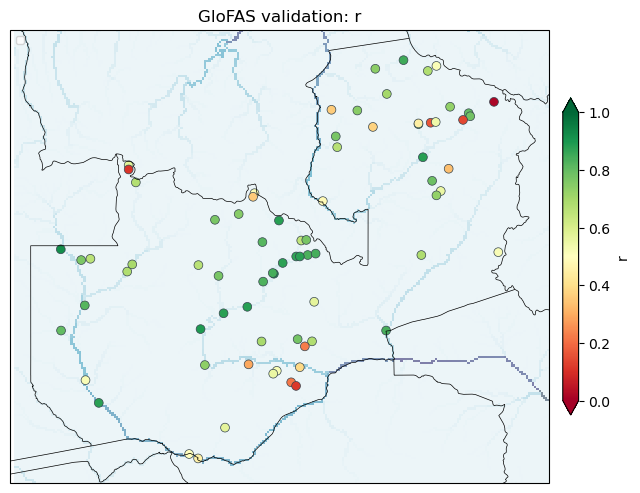

In [32]:
plot_validation_metric_map(
    validation_all_df,
    discharge_bgr=glofas_xr,
    metric="r",
)

KGE and NSE indicators both quantify skill of a hydrological forecast. The following values give some guidance on interpreting specific values.

| Quality assessment | KGE | NSE |
|--------------------|------------|------------|
| Very good          | 0.75 < KGE <= 1.00 | 0.75 < NSE <= 1.00 |
| Good               | 0.50 < KGE <= 0.75 | 0.65 < NSE <= 0.75 |
| Satisfactory       | 0.00 < KGE <= 0.50 | 0.50 < NSE <= 0.65 |
| Unsatisfactory     | KGE <= 0.00       | NSE <= 0.50       |

**References:**

1. Moriasi et al. (2007). *Model Evaluation Guidelines for Systematic
   Quantification of Accuracy in Watershed Simulations*.
   Transactions of the ASABE, 50(3), 885–900.
   https://doi.org/10.13031/2013.23153

2. Knoben et al. (2019). *Technical note: Inherent benchmark or not?
   Comparing Nash–Sutcliffe and Kling–Gupta efficiency scores*.
   Hydrology and Earth System Sciences, 23, 4323–4331.
   https://doi.org/10.5194/hess-23-4323-2019

/var/folders/qn/vpndfm21795ckkq89np1ckp40000gn/T/ipykernel_11938/3489810716.py:96: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(loc="upper left", fontsize=8)


(<Figure size 700x500 with 2 Axes>,
 <GeoAxes: title={'center': 'GloFAS validation: KGE'}, xlabel='longitude [degrees_east]', ylabel='latitude [degrees_north]'>)

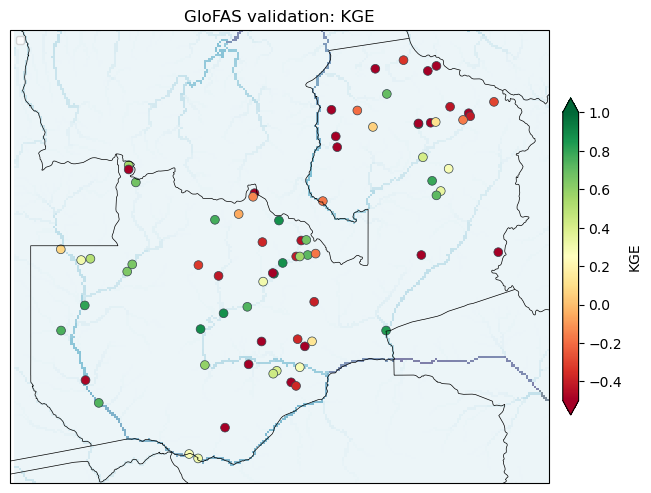

In [33]:
plot_validation_metric_map(
    validation_all_df,
    metric="KGE",
    discharge_bgr=glofas_xr,
    metric_min=-0.5,
    metric_max=1
)

/var/folders/qn/vpndfm21795ckkq89np1ckp40000gn/T/ipykernel_11938/3489810716.py:96: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(loc="upper left", fontsize=8)


(<Figure size 700x500 with 2 Axes>,
 <GeoAxes: title={'center': 'GloFAS validation: NSE'}, xlabel='longitude [degrees_east]', ylabel='latitude [degrees_north]'>)

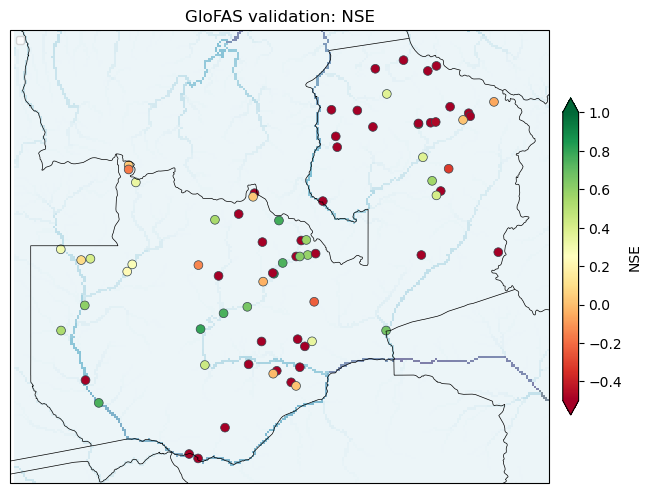

In [34]:
plot_validation_metric_map(
    validation_all_df,
    metric="NSE",
    discharge_bgr=glofas_xr,
    metric_min=-0.5,
    metric_max=1
)

## Location of powerplants

To make this part run, a file should be provided for coordinates of powerplants:

In [35]:
ppl_fl = Path("powerplants/custom_powerplants.csv")

In [36]:
ppl_hydro_df = pd.read_csv(ppl_fl, index_col=0)

ppl_hydro_df = ppl_hydro_df.loc[ppl_hydro_df["Fueltype"].eq("Hydro")].copy()
ppl_hydro_df["Capacity"] = pd.to_numeric(ppl_hydro_df["Capacity"], errors="coerce")
POWER_THRESHOLD_MW = 100  # Classification threshold, not a physical storage criterio
ppl_hydro_df["category"] = np.select(
    [
        ppl_hydro_df["Technology"].eq("Reservoir") & ppl_hydro_df["Capacity"].ge(POWER_THRESHOLD_MW),
        ppl_hydro_df["Technology"].eq("Reservoir"),
    ],
    ["Large reservoir", "Small reservoir"],
    default="Run-of-river / other",
)

Let's check overlap of power generators and observation posts.

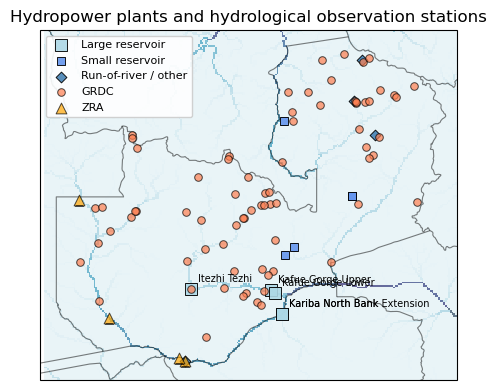

In [37]:
fig, ax = plt.subplots(
    figsize=(6, 4),
    subplot_kw={"projection": ccrs.PlateCarree()},
)

# GloFAS background
glofas_xr["avg_dis"].mean(dim="valid_time").plot(
    ax=ax,
    cmap=cmap_blue_ocean,
    alpha=0.6,
    add_colorbar=False,
    transform=ccrs.PlateCarree(),
    zorder=1,
)

ax.add_feature(
    cfeature.BORDERS,
    edgecolor="black",
    linewidth=0.8,
    zorder=2,
    alpha=0.5,
)

# Hydropower plants
for category, color, marker, size in [
    ("Large reservoir", "lightblue", "s", 80),
    ("Small reservoir", "cornflowerblue", "s", 40),
    ("Run-of-river / other", "steelblue", "D", 30),
]:
    sub = ppl_hydro_df[
        ppl_hydro_df["category"] == category
    ]

    ax.scatter(
        sub["lon"],
        sub["lat"],
        marker=marker,
        s=size,
        facecolor=color,
        edgecolor="black",
        linewidth=0.7,
        alpha=0.9,
        label=category,
        transform=ccrs.PlateCarree(),
        zorder=3,
    )

for source, color, marker, size in [
    ("GRDC", "coral", "o", 30),
    ("ZRA", "orange", "^", 60),
]:
    sub = measurement_stations[
        measurement_stations["source"] == source
    ]

    ax.scatter(
        sub["lon"],
        sub["lat"],
        marker=marker,
        s=size,
        facecolor=color,
        edgecolor="black",
        linewidth=0.7,
        alpha=0.7,
        label=source,
        transform=ccrs.PlateCarree(),
        zorder=4,
    )

large_reservoirs = ppl_hydro_df[
    ppl_hydro_df["category"] == "Large reservoir"
]

for _, plant in large_reservoirs.iterrows():
    ax.annotate(
        plant["Name"],
        (plant["lon"], plant["lat"]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=7,
        transform=ccrs.PlateCarree(),
        zorder=5,
    )

ax.set_extent(
    [21.5, 34, -18.5, -8],
    crs=ccrs.PlateCarree(),
)

ax.legend(
    loc="upper left",
    fontsize=8,
    framealpha=0.9,
)

ax.set_title("Hydropower plants and hydrological observation stations")

plt.tight_layout()
plt.show()